In [1]:
import os
import re
import pdfplumber
import pandas as pd
import numpy as np
import random
from tqdm import tqdm
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
nltk.download('punkt')
from sklearn.metrics.pairwise import cosine_distances

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\aznur\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [2]:
def extract_text_from_folder(folder_path):
    all_text = []
    for filename in tqdm(os.listdir(folder_path), desc="Extracting PDFs"):
        if filename.endswith('.pdf'):
            pdf_path = os.path.join(folder_path, filename)
            with pdfplumber.open(pdf_path) as pdf:
                text = ""
                for page in pdf.pages:
                    text += page.extract_text()
                all_text.append(text)
    return all_text

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = word_tokenize(text)
    return tokens

def train_word2vec(tokens_list, vector_size=100, window=5, min_count=1, sg=0):
    model = Word2Vec(
        tokens_list,
        vector_size=vector_size,
        window=window,
        min_count=min_count,
        sg=sg
    )
    return model

# Applied Catalysis A: General

In [3]:
pdf_folder_path = 'C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A'
pdf_text = extract_text_from_folder(pdf_folder_path)

In [4]:
preprocessed_text = [preprocess_text(text) for text in pdf_text]

In [5]:
word2vec_model = train_word2vec(preprocessed_text)

In [6]:
word2vec_model.save("C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A/word2vec_model.model")

In [3]:
loaded_model = Word2Vec.load("C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A/word2vec_model.model")

In [4]:
word_embedding = loaded_model.wv['catalysis']
print("Word embedding for 'catalysis':", word_embedding)

Word embedding for 'catalysis': [ 0.63083416  3.357243   -1.0249403  -0.54581714 -0.9355507  -1.070068
  1.9617262   2.8641682  -2.952195   -3.1014378   0.57620513 -3.5827098
  0.70658284 -1.2899007   3.604752   -1.2232536   1.9947066  -0.49424472
  0.8712979  -3.4019043   2.363861    0.01284702  0.46866882 -0.24851936
 -3.1085644  -0.3501955  -2.139588   -0.8727895  -1.6949908   0.46846655
  2.7891624  -1.9694358   0.46292618 -1.9749147   0.46311268  2.188874
 -0.03693309  1.0576223  -1.8894192  -0.04289824  0.0152453  -1.8065637
  0.2112628   0.7558707   2.0956833  -1.6174127  -1.8722615  -0.77135587
 -0.5157288  -0.35178167  1.7982866  -1.1668147  -1.387298   -2.7341433
  0.6336446   0.46987066  0.7243772  -1.5174413  -1.5399473   0.95053285
 -0.621274    0.349468    0.7798203  -0.24163549 -0.09400903  0.37765294
  3.871086    1.0997871  -2.8581371   0.18775192  0.30534425 -0.9080552
  0.5003084   0.9987038   2.0330882   2.1432006   0.37279278  1.812058
 -3.1604307   1.4533633  -2.0

In [5]:
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A/gender_dimensions/most_common_new.csv')

In [6]:
energy = [word for word in energy['Word'] if len(word) > 3]
energy = energy[:15]

In [7]:
male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

In [8]:
words = energy+male_words+female_words

In [9]:
# Assuming you have loaded your word embeddings into word_embedding
valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = loaded_model.wv[word]  # Use the wv attribute to access word vectors
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass
#         valid_words.append(word)
#         valid_dict_words_vector[word] = [0] * 100

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)

In [10]:
new=pd.DataFrame(all_values)
new.index=valid_words

In [11]:
new

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
catalysis,0.630834,3.357243,-1.024940,-0.545817,-0.935551,-1.070068,1.961726,2.864168,-2.952195,-3.101438,...,2.733198,0.717151,0.062546,-1.746402,2.276857,-0.348635,-0.617929,-2.816555,0.039757,0.809638
applied,0.537235,3.094534,-0.869898,-0.501441,-1.048821,-0.843197,1.748380,2.468700,-2.909451,-2.794055,...,2.429843,0.464613,0.047577,-1.373921,2.020253,-0.216906,-0.322987,-2.470900,0.006503,0.624260
general,0.571565,3.389106,-0.955155,-0.667023,-0.745189,-0.894459,1.893144,2.580626,-3.032443,-2.872947,...,2.612318,0.743753,0.082741,-1.702322,2.164037,-0.485013,-0.491787,-2.703481,0.142415,0.723224
catalyst,-0.520823,1.658900,0.798142,0.669848,-1.124402,-0.774442,1.367172,2.800677,-2.861180,-1.482455,...,1.543730,1.087011,0.093805,0.779118,2.889778,0.848706,1.836226,-1.429469,0.789606,0.859848
reaction,-0.230307,1.882615,0.847327,0.553028,-1.099880,-0.417331,1.644880,2.849243,-3.293005,-1.425119,...,1.413293,1.068493,0.155039,1.326228,3.209652,0.438433,2.009659,-1.248646,1.282757,1.030959
catalysts,-0.636744,2.081839,0.769760,0.215910,-0.927792,-0.967084,1.333780,3.036772,-2.582317,-2.180668,...,1.405998,0.699540,0.428646,0.875705,2.991592,0.901342,1.525263,-1.611678,0.096873,1.524613
using,-0.403762,2.014584,0.363290,0.172761,-0.821438,-0.521737,1.652103,1.885900,-2.940995,-2.206847,...,1.569428,1.315809,0.445233,0.634401,2.462027,0.037844,1.671791,-0.847122,0.719583,1.295981
high,-0.376991,1.372179,0.509208,0.537378,-0.947940,-0.384777,1.234615,2.242689,-2.060133,-1.093407,...,1.205352,0.804881,0.274803,0.827551,2.498357,0.768892,1.210336,-1.031777,0.643228,0.784042
used,-0.644886,1.905401,0.655066,0.233205,-0.635629,-0.454516,0.972353,2.355566,-2.492933,-1.857532,...,0.939810,0.435052,0.071883,0.797051,2.334605,1.203526,0.663952,-1.324797,0.555230,0.837439
temperature,0.329502,1.144396,1.006761,0.723110,-1.582690,0.077906,1.620798,1.965381,-3.079235,-0.841653,...,1.202718,0.887684,-0.034129,1.155048,2.589763,0.322623,2.231233,-0.490424,1.635288,0.642204


In [12]:
pca = PCA(n_components=2)
result = pca.fit_transform(new)

In [13]:
result

array([[-7.597739  ,  7.9519033 ],
       [-6.278343  ,  7.071008  ],
       [-7.205899  ,  7.997716  ],
       [-2.6410022 , -4.4988203 ],
       [-3.3420544 , -4.9844527 ],
       [-3.1730194 , -3.4497054 ],
       [-3.1166236 , -1.9213952 ],
       [-0.77646935, -3.0261557 ],
       [-1.1923121 , -2.3838465 ],
       [-1.3819604 , -4.7259903 ],
       [-3.382969  , -5.0407147 ],
       [-1.5364153 , -4.3324203 ],
       [ 7.950807  ,  2.1861696 ],
       [ 3.7139485 ,  1.227087  ],
       [ 7.9595933 ,  2.107751  ],
       [ 6.9412293 ,  2.0201702 ],
       [ 7.9418774 ,  2.1089475 ],
       [ 7.1173534 ,  1.6927545 ]], dtype=float32)

In [21]:
from numpy import dot
from numpy.linalg import norm

def cosine_similarity(v1, v2):
    return np.dot(v1, v2) / (norm(v1) * norm(v2))

pronouns = male_words + female_words

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in pronouns]

cosine_similarities = {}

for pronoun in pronouns:
    if pronoun in new.index:
        idx_pronoun = new.index.get_loc(pronoun)
        vec_pronoun = result[idx_pronoun]

        for idx_word in non_pronoun_indices:
            word = new.index[idx_word]
            vec_word = result[idx_word]

            similarity = cosine_similarity(vec_pronoun, vec_word)

            cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")

('man', 'catalysis'): -0.47
('man', 'applied'): -0.44
('man', 'general'): -0.45
('man', 'catalyst'): -0.72
('man', 'reaction'): -0.76
('man', 'catalysts'): -0.85
('man', 'using'): -0.96
('man', 'high'): -0.50
('man', 'used'): -0.67
('man', 'temperature'): -0.53
('man', 'surface'): -0.76
('man', 'activity'): -0.57
('he', 'catalysis'): -0.43
('he', 'applied'): -0.40
('he', 'general'): -0.40
('he', 'catalyst'): -0.75
('he', 'reaction'): -0.79
('he', 'catalysts'): -0.87
('he', 'using'): -0.97
('he', 'high'): -0.54
('he', 'used'): -0.71
('he', 'temperature'): -0.57
('he', 'surface'): -0.79
('he', 'activity'): -0.61
('him', 'catalysis'): -0.48
('him', 'applied'): -0.45
('him', 'general'): -0.46
('him', 'catalyst'): -0.71
('him', 'reaction'): -0.75
('him', 'catalysts'): -0.84
('him', 'using'): -0.96
('him', 'high'): -0.49
('him', 'used'): -0.66
('him', 'temperature'): -0.52
('him', 'surface'): -0.75
('him', 'activity'): -0.56
('his', 'catalysis'): -0.46
('his', 'applied'): -0.43
('his', 'gene

In [22]:
df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

In [23]:
df_cosine_similarities.to_csv('C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A/gender_dimensions/trained_cos_sim.csv', index=False)

In [26]:
avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words if pronoun in new.index]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words if pronoun in new.index]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

Overall average cosine distance to male pronouns: 1.6426
Overall average cosine distance to female pronouns: 1.6324


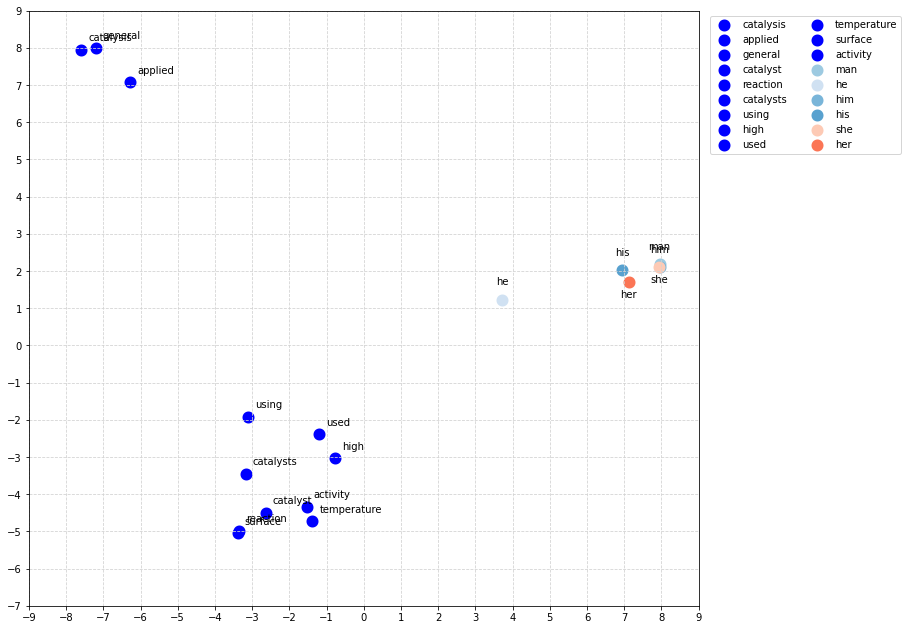

In [34]:
# Create a dictionary to map words to colors
word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

# Create a set of opposing pronouns
opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

# Generate different colors for opposing sets of pronouns
unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))  # Set the figure size for better control of aspect ratio
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")  # Default to blue if word not in dictionary
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:  # Add annotation for non-pronoun words
        offset = (7, 9)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        
# Move the legend outside and adjust its position
plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')  # Set equal aspect ratio
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/Applied Catalysis A/gender_dimensions/word2vec_trained.png', bbox_inches='tight')
plt.show()

# Training models for other journals

In [126]:
journals = ['International Journal of Greenhouse Gas Control',
           'International Journal of Hydrogen Energy',
           'Solar Energy', 'Transport in Porous Media']

for journal in journals:
    
    # Path to the folder containing PDF files
    pdf_folder_path = f'C:/Users/aznur/Desktop/Projects/data_extraction/{journal}'
    
    print('Extracting text from: ', journal)

    # Extract text from PDF files
    pdf_text = extract_text_from_folder(pdf_folder_path)
    
    print('Preprocessing text from: ', journal)

    # Preprocess text data
    preprocessed_text = [preprocess_text(text) for text in pdf_text]
    
    print('Training Word2Vec model for: ', journal)

    # Train Word2Vec model
    word2vec_model = train_word2vec(preprocessed_text)
    
    print('Saving the Word2Vec model for: ', journal)

    # Save the Word2Vec model
    word2vec_model.save(f"C:/Users/aznur/Desktop/Projects/data_extraction/{journal}/word2vec_model.model")

Extracting text from:  International Journal of Greenhouse Gas Control


Extracting PDFs: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 304/304 [38:15<00:00,  7.55s/it]


Preprocessing text from:  International Journal of Greenhouse Gas Control
Training Word2Vec model for:  International Journal of Greenhouse Gas Control
Saving the Word2Vec model for:  International Journal of Greenhouse Gas Control
Extracting text from:  International Journal of Hydrogen Energy


Extracting PDFs: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 873/873 [45:11<00:00,  3.11s/it]


Preprocessing text from:  International Journal of Hydrogen Energy
Training Word2Vec model for:  International Journal of Hydrogen Energy
Saving the Word2Vec model for:  International Journal of Hydrogen Energy
Extracting text from:  Solar Energy


Extracting PDFs: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 306/306 [21:44<00:00,  4.26s/it]


Preprocessing text from:  Solar Energy
Training Word2Vec model for:  Solar Energy
Saving the Word2Vec model for:  Solar Energy
Extracting text from:  Transport in Porous Media


Extracting PDFs: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 364/364 [39:38<00:00,  6.54s/it]


Preprocessing text from:  Transport in Porous Media
Training Word2Vec model for:  Transport in Porous Media
Saving the Word2Vec model for:  Transport in Porous Media


# Word embeddings visualisation for other journals

In [27]:
# Load the saved model
loaded_model = Word2Vec.load("C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Greenhouse Gas Control/word2vec_model.model")
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Greenhouse Gas Control/gender_dimensions/most_common_new.csv')

In [28]:
energy = [word for word in energy['Word'] if len(word) > 3]
energy = energy[:15]

In [29]:
male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

In [30]:
words = energy+male_words+female_words

In [31]:
# Assuming you have loaded your word embeddings into word_embedding
valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = loaded_model.wv[word]  # Use the wv attribute to access word vectors
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass
#         valid_words.append(word)
#         valid_dict_words_vector[word] = [0] * 100

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)

In [32]:
new=pd.DataFrame(all_values)
new.index=valid_words

In [33]:
new

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
control,-1.330606,1.942470,-0.057012,0.594736,0.568476,-0.174854,-0.283707,3.024585,-2.275252,-1.564643,...,0.493609,0.122868,-0.937072,-0.130199,2.997703,1.153095,1.326903,0.007611,0.099962,0.098522
international,-2.482863,3.202236,-0.574355,1.323903,0.038290,-0.923718,-0.279368,2.116966,-2.655776,-0.973295,...,0.666929,0.746732,-0.198695,0.209742,3.451696,1.556600,2.106953,0.572601,-0.366224,-0.084735
journal,-2.503821,3.404675,-0.468780,1.348288,-0.164600,-0.735016,-0.081622,3.098343,-2.760688,-2.048513,...,1.696323,-0.024630,-0.321077,0.461418,3.602734,1.432802,2.153701,0.501684,-1.318995,-0.029044
greenhouse,-2.261789,3.048397,-0.429696,0.482561,0.125957,-0.549432,-1.618996,2.311498,-2.637294,-1.770302,...,0.926910,0.402919,-0.709517,0.404265,2.725242,1.236822,1.818983,0.815318,-0.649193,-0.245269
carbon,1.163489,2.967436,0.000406,-0.022016,-1.657039,-1.596174,0.686401,-0.038227,-2.167301,-0.542232,...,-0.682830,1.172432,2.358923,-1.493590,1.486078,0.037794,1.998442,-0.129626,1.331272,-0.964656
storage,0.050777,2.165043,-0.903880,0.083048,-2.790224,-2.131097,2.644892,2.127333,-4.182847,-2.786915,...,-0.112926,1.516847,1.588731,-0.840137,1.822467,0.936485,1.264050,-1.068511,1.352329,-1.033225
using,0.173266,0.802796,0.329654,0.768202,2.214729,-0.664069,3.118883,3.153115,-2.202398,0.165028,...,1.511471,-0.089359,1.849521,-0.024635,4.083017,1.344271,1.501379,-1.345533,0.753150,-0.819557
used,0.631295,0.462715,-0.933552,0.495348,0.015002,0.338776,2.992856,4.337449,-2.011680,-0.055007,...,1.091219,-0.563384,0.865118,-0.910108,3.129916,1.279282,0.313815,-2.020965,1.630977,-0.137384
capture,0.326874,3.601221,-1.048237,-0.513441,-1.154803,-2.107126,1.444139,0.611212,-3.558517,-1.123962,...,-1.126214,-1.057883,-0.272180,-1.812251,3.287200,0.695512,-1.482254,-1.574488,1.460095,-1.112904
energy,-1.309746,3.158201,-0.303867,-0.038086,-0.202750,-1.859460,0.647155,1.514030,-2.870511,-0.864782,...,-0.116078,0.449404,1.079185,-1.476942,2.783318,0.940650,0.568533,-1.406545,1.455715,-0.905103


In [34]:
pca = PCA(n_components=2)
result = pca.fit_transform(new)

In [35]:
result

array([[ 7.37851   , -1.6637493 ],
       [12.600953  , -3.6002512 ],
       [14.116973  , -2.3628225 ],
       [12.971587  , -5.5942583 ],
       [ 2.7793581 ,  2.6942604 ],
       [ 1.2572528 ,  7.165697  ],
       [-1.8839089 ,  4.712164  ],
       [-2.2629004 ,  4.8321643 ],
       [-0.2990153 ,  5.9025235 ],
       [ 3.2226515 ,  3.0157678 ],
       [-0.36061195,  2.609938  ],
       [-2.853621  ,  6.7488303 ],
       [-1.6200573 ,  5.0993857 ],
       [-2.2426221 ,  6.633127  ],
       [-2.726231  ,  6.211212  ],
       [-5.5634437 , -5.5910606 ],
       [-5.422387  , -5.692504  ],
       [-2.1168628 , -3.4260495 ],
       [-5.717158  , -5.7424116 ],
       [-4.7604423 , -4.9953694 ],
       [-5.384732  , -5.5073247 ],
       [-5.8715825 , -5.8596563 ],
       [-5.241708  , -5.58962   ]], dtype=float32)

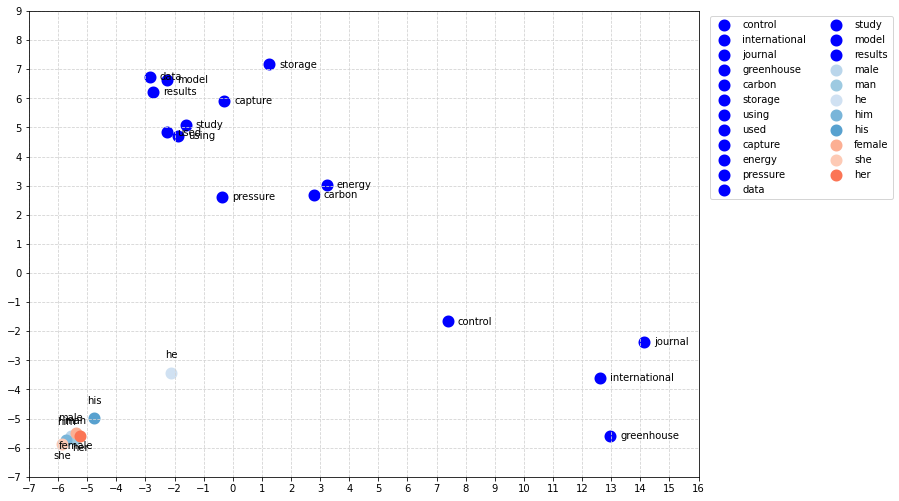

In [36]:
# Create a dictionary to map words to colors
word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

# Calculate the minimum and maximum values for both dimensions
x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

# Create a set of opposing pronouns
opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

# Generate different colors for opposing sets of pronouns
unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))  # Set the figure size for better control of aspect ratio
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")  # Default to blue if word not in dictionary
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:  # Add annotation for non-pronoun words
        offset = (10, -3)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        
# plt.title("Word Embedding Space (International Journal of Greenhouse Gas Control)", size=20)
# Move the legend outside and adjust its position
plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')  # Set equal aspect ratio
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Greenhouse Gas Control/gender_dimensions/words_trained.png', bbox_inches='tight')
plt.show()

In [37]:
pronouns = male_words + female_words

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in pronouns]

cosine_similarities = {}

for pronoun in pronouns:
    if pronoun in new.index:
        idx_pronoun = new.index.get_loc(pronoun)
        vec_pronoun = result[idx_pronoun]

        for idx_word in non_pronoun_indices:
            word = new.index[idx_word]
            vec_word = result[idx_word]

            similarity = cosine_similarity(vec_pronoun, vec_word)

            cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")
    
df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

df_cosine_similarities.to_csv('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Greenhouse Gas Control/gender_dimensions/trained_cos_sim.csv', index=False)

avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words if pronoun in new.index]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words if pronoun in new.index]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

('male', 'control'): -0.53
('male', 'international'): -0.48
('male', 'journal'): -0.58
('male', 'greenhouse'): -0.37
('male', 'carbon'): -1.00
('male', 'storage'): -0.82
('male', 'using'): -0.40
('male', 'used'): -0.34
('male', 'capture'): -0.67
('male', 'energy'): -1.00
('male', 'pressure'): -0.61
('male', 'data'): -0.38
('male', 'study'): -0.46
('male', 'model'): -0.45
('male', 'results'): -0.37
('man', 'control'): -0.51
('man', 'international'): -0.46
('man', 'journal'): -0.56
('man', 'greenhouse'): -0.35
('man', 'carbon'): -1.00
('man', 'storage'): -0.83
('man', 'using'): -0.42
('man', 'used'): -0.36
('man', 'capture'): -0.69
('man', 'energy'): -1.00
('man', 'pressure'): -0.62
('man', 'data'): -0.40
('man', 'study'): -0.48
('man', 'model'): -0.47
('man', 'results'): -0.39
('he', 'control'): -0.33
('he', 'international'): -0.27
('he', 'journal'): -0.38
('he', 'greenhouse'): -0.15
('he', 'carbon'): -0.97
('he', 'storage'): -0.93
('he', 'using'): -0.59
('he', 'used'): -0.55
('he', 'ca

In [38]:
# Load the saved model
loaded_model = Word2Vec.load("C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Hydrogen Energy/word2vec_model.model")
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Hydrogen Energy/gender_dimensions/most_common_new.csv')

In [39]:
energy = [word for word in energy['Word'] if len(word) > 3]
energy = energy[:15]

male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy+male_words+female_words

# Assuming you have loaded your word embeddings into word_embedding
valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = loaded_model.wv[word]  # Use the wv attribute to access word vectors
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass
#         valid_words.append(word)
#         valid_dict_words_vector[word] = [0] * 100

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)
    
new=pd.DataFrame(all_values)
new.index=valid_words
    
pca = PCA(n_components=2)
result = pca.fit_transform(new)

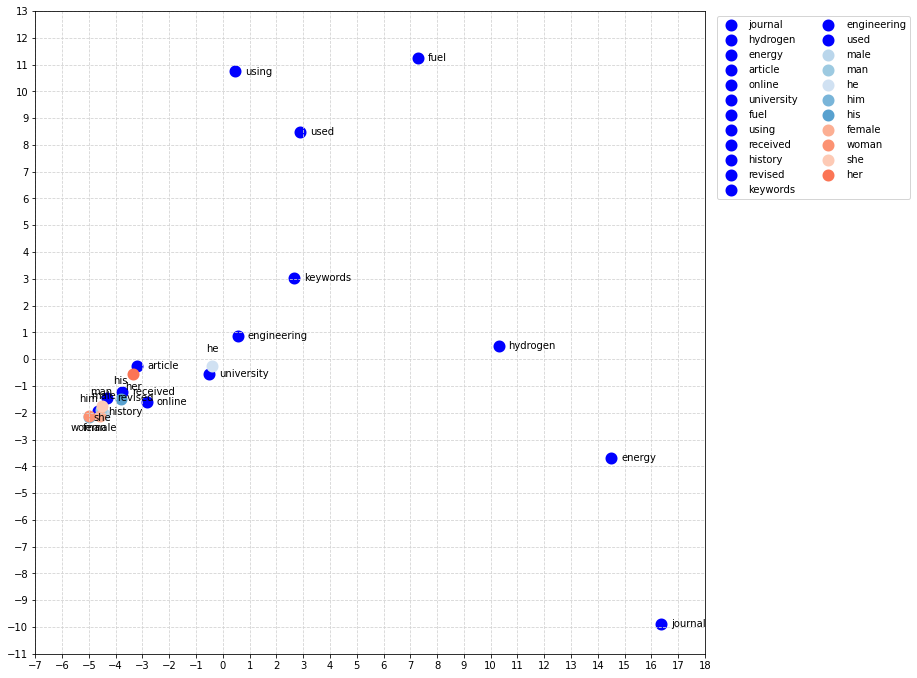

In [40]:
# Create a dictionary to map words to colors
word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

# Calculate the minimum and maximum values for both dimensions
x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

# Create a set of opposing pronouns
opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

# Generate different colors for opposing sets of pronouns
unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))  # Set the figure size for better control of aspect ratio
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")  # Default to blue if word not in dictionary
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:  # Add annotation for non-pronoun words
        offset = (10, -3)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        
# plt.title("Word Embedding Space (International Journal of Greenhouse Gas Control)", size=20)
# Move the legend outside and adjust its position
plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')  # Set equal aspect ratio
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Hydrogen Energy/gender_dimensions/words_trained.png', bbox_inches='tight')
plt.show()

In [41]:
pronouns = male_words + female_words

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in pronouns]

cosine_similarities = {}

for pronoun in pronouns:
    if pronoun in new.index:
        idx_pronoun = new.index.get_loc(pronoun)
        vec_pronoun = result[idx_pronoun]

        for idx_word in non_pronoun_indices:
            word = new.index[idx_word]
            vec_word = result[idx_word]

            similarity = cosine_similarity(vec_pronoun, vec_word)

            cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")
    
df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

df_cosine_similarities.to_csv('C:/Users/aznur/Desktop/Projects/data_extraction/International Journal of Hydrogen Energy/gender_dimensions/trained_cos_sim.csv', index=False)

avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words if pronoun in new.index]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words if pronoun in new.index]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

('male', 'journal'): -0.56
('male', 'hydrogen'): -0.93
('male', 'energy'): -0.78
('male', 'article'): 0.94
('male', 'online'): 1.00
('male', 'university'): 0.93
('male', 'fuel'): -0.84
('male', 'using'): -0.45
('male', 'received'): 0.99
('male', 'history'): 1.00
('male', 'revised'): 0.99
('male', 'keywords'): -0.91
('male', 'engineering'): -0.84
('male', 'used'): -0.68
('man', 'journal'): -0.59
('man', 'hydrogen'): -0.94
('man', 'energy'): -0.80
('man', 'article'): 0.95
('man', 'online'): 0.99
('man', 'university'): 0.91
('man', 'fuel'): -0.82
('man', 'using'): -0.42
('man', 'received'): 1.00
('man', 'history'): 1.00
('man', 'revised'): 1.00
('man', 'keywords'): -0.90
('man', 'engineering'): -0.82
('man', 'used'): -0.66
('he', 'journal'): -0.42
('he', 'hydrogen'): -0.85
('he', 'energy'): -0.66
('he', 'article'): 0.87
('he', 'online'): 1.00
('he', 'university'): 0.98
('he', 'fuel'): -0.92
('he', 'using'): -0.60
('he', 'received'): 0.96
('he', 'history'): 0.98
('he', 'revised'): 0.96
('h

In [42]:
# Load the saved model
loaded_model = Word2Vec.load("C:/Users/aznur/Desktop/Projects/data_extraction/Solar Energy/word2vec_model.model")
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/Solar Energy/gender_dimensions/most_common_new.csv')

In [43]:
energy = [word for word in energy['Word'] if len(word) > 3]
energy = energy[:15]

energy = random.sample(energy, 10)

male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy+male_words+female_words

# Assuming you have loaded your word embeddings into word_embedding
valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = loaded_model.wv[word]  # Use the wv attribute to access word vectors
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass
#         valid_words.append(word)
#         valid_dict_words_vector[word] = [0] * 100

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)
    
new=pd.DataFrame(all_values)
new.index=valid_words
    
pca = PCA(n_components=2)
result = pca.fit_transform(new)

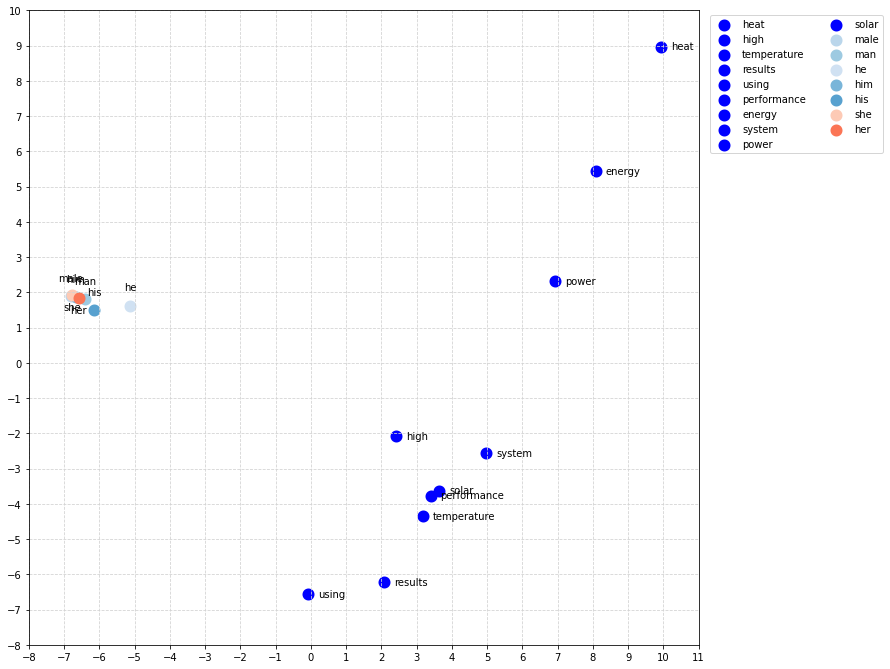

In [44]:
# Create a dictionary to map words to colors
word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

# Calculate the minimum and maximum values for both dimensions
x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

# Create a set of opposing pronouns
opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

# Generate different colors for opposing sets of pronouns
unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))  # Set the figure size for better control of aspect ratio
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")  # Default to blue if word not in dictionary
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:  # Add annotation for non-pronoun words
        offset = (10, -3)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        
# plt.title("Word Embedding Space (International Journal of Greenhouse Gas Control)", size=20)
# Move the legend outside and adjust its position
plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')  # Set equal aspect ratio
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/Solar Energy/gender_dimensions/words_trained.png', bbox_inches='tight')
plt.show()

In [45]:
pronouns = male_words + female_words

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in pronouns]

cosine_similarities = {}

for pronoun in pronouns:
    if pronoun in new.index:
        idx_pronoun = new.index.get_loc(pronoun)
        vec_pronoun = result[idx_pronoun]

        for idx_word in non_pronoun_indices:
            word = new.index[idx_word]
            vec_word = result[idx_word]

            similarity = cosine_similarity(vec_pronoun, vec_word)

            cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")
    
df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

df_cosine_similarities.to_csv('C:/Users/aznur/Desktop/Projects/data_extraction/Solar Energy/gender_dimensions/trained_cos_sim.csv', index=False)

avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words if pronoun in new.index]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words if pronoun in new.index]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

('male', 'heat'): -0.53
('male', 'high'): -0.91
('male', 'temperature'): -0.79
('male', 'results'): -0.56
('male', 'using'): -0.26
('male', 'performance'): -0.84
('male', 'energy'): -0.65
('male', 'system'): -0.98
('male', 'power'): -0.83
('male', 'solar'): -0.87
('man', 'heat'): -0.53
('man', 'high'): -0.91
('man', 'temperature'): -0.79
('man', 'results'): -0.56
('man', 'using'): -0.26
('man', 'performance'): -0.85
('man', 'energy'): -0.65
('man', 'system'): -0.98
('man', 'power'): -0.83
('man', 'solar'): -0.87
('he', 'heat'): -0.51
('he', 'high'): -0.92
('he', 'temperature'): -0.81
('he', 'results'): -0.59
('he', 'using'): -0.29
('he', 'performance'): -0.86
('he', 'energy'): -0.62
('he', 'system'): -0.99
('he', 'power'): -0.81
('he', 'solar'): -0.89
('him', 'heat'): -0.53
('him', 'high'): -0.91
('him', 'temperature'): -0.79
('him', 'results'): -0.56
('him', 'using'): -0.26
('him', 'performance'): -0.85
('him', 'energy'): -0.65
('him', 'system'): -0.98
('him', 'power'): -0.83
('him', 

In [46]:
# Load the saved model
loaded_model = Word2Vec.load("C:/Users/aznur/Desktop/Projects/data_extraction/Transport in Porous Media/word2vec_model.model")
energy = pd.read_csv('C:/Users/aznur/Desktop/Projects/data_extraction/Transport in Porous Media/gender_dimensions/most_common_new.csv')

In [47]:
energy = [word for word in energy['Word'] if len(word) > 3]
energy = energy[:15]

male_words = ['male', 'man', 'he', 'him', 'his']
female_words = ['female', 'woman', 'she', 'her', 'hers']

words = energy+male_words+female_words

# Assuming you have loaded your word embeddings into word_embedding
valid_words = []
valid_dict_words_vector = {}

for word in words:
    try:
        vector = loaded_model.wv[word]  # Use the wv attribute to access word vectors
        valid_words.append(word)
        valid_dict_words_vector[word] = vector
    except KeyError:
        pass
#         valid_words.append(word)
#         valid_dict_words_vector[word] = [0] * 100

all_values = []
for key, values in valid_dict_words_vector.items():
    all_values.append(values)
    
new=pd.DataFrame(all_values)
new.index=valid_words
    
pca = PCA(n_components=2)
result = pca.fit_transform(new)

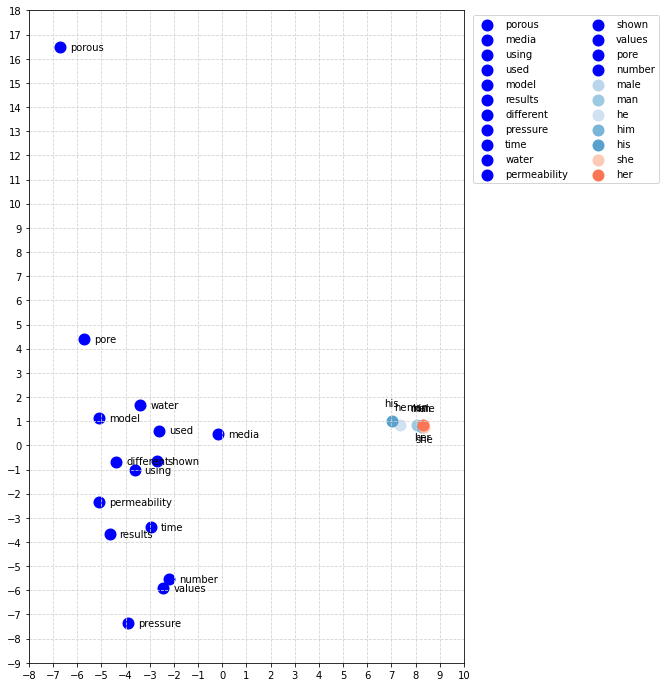

In [48]:
# Create a dictionary to map words to colors
word_colours = {
    "he": "blue",
    "male": "blue",
    "man": "blue",
    "him": "blue",
    "his": "blue",
    "she": "red",
    "female": "red",
    "woman": "red",
    "her": "red",
    "hers": "red",
}

# Calculate the minimum and maximum values for both dimensions
x_min = np.floor(result[:, 0].min())
x_max = np.ceil(result[:, 0].max())
y_min = np.floor(result[:, 1].min())
y_max = np.ceil(result[:, 1].max())

# Create a set of opposing pronouns
opposing_sets = [("he", "she"), ("male", "female"), ("man", "woman"), ("him", "her"), ("his", "hers")]

# Generate different colors for opposing sets of pronouns
unique_colors_cold = iter(plt.cm.Blues(np.linspace(0.2, 1, len(opposing_sets) * 2)))
unique_colors_warm = iter(plt.cm.Reds(np.linspace(0.2, 1, len(opposing_sets) * 2)))

for i, (pronoun1, pronoun2) in enumerate(opposing_sets):
    word_colours[pronoun1] = next(unique_colors_cold)
    word_colours[pronoun2] = next(unique_colors_warm)
    
plt.figure(figsize=(12, 12))  # Set the figure size for better control of aspect ratio
for i, word in enumerate(new.index):
    color = word_colours.get(word, "blue")  # Default to blue if word not in dictionary
    plt.scatter(result[i, 0], result[i, 1], linewidths=6, color=color, label=word)

    if word not in word_colours:  # Add annotation for non-pronoun words
        offset = (10, -3)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='left', fontsize=10, color='black')
    if word in male_words:
        offset = (0, 15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
    if word in female_words:
        offset = (0, -15)
        plt.annotate(word, (result[i, 0], result[i, 1]), textcoords="offset points", xytext=offset, ha='center', fontsize=10, color='black')
        
# plt.title("Word Embedding Space (International Journal of Greenhouse Gas Control)", size=20)
# Move the legend outside and adjust its position
plt.legend(ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(color='lightgray', linestyle='--')
plt.gca().set_aspect('equal')  # Set equal aspect ratio
plt.xticks(np.arange(x_min-1, x_max + 1.1, 1))
plt.yticks(np.arange(y_min-1, y_max + 1.1, 1))
plt.xlim(x_min-1, x_max+1)
plt.ylim(y_min-1, y_max+1)
plt.savefig('C:/Users/aznur/Desktop/Projects/data_extraction/Transport in Porous Media/gender_dimensions/words_trained.png', bbox_inches='tight')
plt.show()

In [49]:
pronouns = male_words + female_words

non_pronoun_indices = [i for i, word in enumerate(new.index) if word not in pronouns]

cosine_similarities = {}

for pronoun in pronouns:
    if pronoun in new.index:
        idx_pronoun = new.index.get_loc(pronoun)
        vec_pronoun = result[idx_pronoun]

        for idx_word in non_pronoun_indices:
            word = new.index[idx_word]
            vec_word = result[idx_word]

            similarity = cosine_similarity(vec_pronoun, vec_word)

            cosine_similarities[(pronoun, word)] = similarity

for pair, sim in cosine_similarities.items():
    print(f"{pair}: {sim:.2f}")
    
df_cosine_similarities = pd.DataFrame(list(cosine_similarities.items()), columns=['Pairs', 'Cosine Similarity'])

df_cosine_similarities[['Pronoun', 'Word']] = pd.DataFrame(df_cosine_similarities['Pairs'].tolist(), index=df_cosine_similarities.index)

df_cosine_similarities = df_cosine_similarities.drop(columns='Pairs')

df_cosine_similarities = df_cosine_similarities[['Pronoun', 'Word', 'Cosine Similarity']]

df_cosine_similarities.to_csv('C:/Users/aznur/Desktop/Projects/data_extraction/Transport in Porous Media/gender_dimensions/trained_cos_sim.csv', index=False)

avg_distances_male = []
avg_distances_female = []

for idx_word in non_pronoun_indices:
    word = new.index[idx_word]
    vec_word = result[idx_word]

    distances_male = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in male_words if pronoun in new.index]
    distances_female = [1 - cosine_similarity(vec_word, result[new.index.get_loc(pronoun)]) for pronoun in female_words if pronoun in new.index]

    avg_distances_male.append(np.mean(distances_male))
    avg_distances_female.append(np.mean(distances_female))

overall_avg_male = np.mean(avg_distances_male)
overall_avg_female = np.mean(avg_distances_female)

print(f"Overall average cosine distance to male pronouns: {overall_avg_male:.4f}")
print(f"Overall average cosine distance to female pronouns: {overall_avg_female:.4f}")

('male', 'porous'): -0.29
('male', 'media'): -0.28
('male', 'using'): -0.98
('male', 'used'): -0.95
('male', 'model'): -0.95
('male', 'results'): -0.84
('male', 'different'): -1.00
('male', 'pressure'): -0.55
('male', 'time'): -0.73
('male', 'water'): -0.85
('male', 'permeability'): -0.94
('male', 'shown'): -0.99
('male', 'values'): -0.47
('male', 'pore'): -0.73
('male', 'number'): -0.46
('man', 'porous'): -0.28
('man', 'media'): -0.27
('man', 'using'): -0.99
('man', 'used'): -0.94
('man', 'model'): -0.95
('man', 'results'): -0.85
('man', 'different'): -1.00
('man', 'pressure'): -0.56
('man', 'time'): -0.73
('man', 'water'): -0.85
('man', 'permeability'): -0.95
('man', 'shown'): -0.99
('man', 'values'): -0.47
('man', 'pore'): -0.73
('man', 'number'): -0.46
('he', 'porous'): -0.27
('he', 'media'): -0.27
('he', 'using'): -0.99
('he', 'used'): -0.94
('he', 'model'): -0.95
('he', 'results'): -0.85
('he', 'different'): -1.00
('he', 'pressure'): -0.56
('he', 'time'): -0.74
('he', 'water'): -